# Credit Risk Scorecard — Bước 4: Validation, Calibration & Model Card
**Input:** `model_lr.pkl` · `cs_scores.csv` · `cs_woe_transformed.csv` · `woe_bins.pkl`  
**Output:** `model_card.md` · `psi_report.csv` · `validation_report.png`

---
### Cấu trúc notebook
1. Reload artifacts từ Bước 3
2. Calibration check — Reliability Diagram
3. Threshold optimization — Precision / Recall trade-off
4. Population Stability Index (PSI)
5. Gains & Lift Table
6. Backtesting — Basel Traffic Light
7. Top Reason Codes (giải thích từng khách hàng)
8. Tổng hợp Validation Report
9. Xuất Model Card (Markdown)

## Tại sao cần Validation riêng sau khi có AUC?

AUC chỉ đo khả năng **xếp hạng** (ranking) — không đảm bảo xác suất được calibrate đúng.  
Ví dụ: model có AUC = 0.80 nhưng predict P(bad) = 0.03 cho khách hàng thực ra có bad rate 8%  
→ **Ngân hàng định giá lãi suất sai** → thua lỗ.

Validation đầy đủ cần kiểm tra thêm:

| Kiểm tra | Câu hỏi | Công cụ |
|---|---|---|
| Calibration | Xác suất predict có đúng không? | Reliability diagram, Brier score |
| Stability | Model có drift theo thời gian không? | PSI |
| Business value | Có thực sự giúp capture bad hơn random? | Gains/Lift table |
| Regulatory | Có đạt ngưỡng Basel không? | Traffic light test |
| Explainability | Tại sao khách hàng bị từ chối? | Reason codes |

#### 1. Reload Artifact

In [11]:
import warnings, pickle, json
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.calibration   import calibration_curve, CalibratedClassifierCV
from sklearn.metrics       import (roc_auc_score, roc_curve, brier_score_loss,
                                   precision_recall_curve, average_precision_score,
                                   confusion_matrix, classification_report)
from sklearn.model_selection import train_test_split
import scorecardpy as sc

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
})
PALETTE = {"good": "#2196F3", "bad": "#E53935", "neutral": "#78909C"}

# ── Load artifacts ────────────────────────────────────────────────────────────
with open("../Logistic regression/model_lr.pkl",     "rb") as f: lr_model   = pickle.load(f)
with open("../WOE_IV/woe_bins.pkl",     "rb") as f: bins_final = pickle.load(f)
with open("../WOE_IV/selected_vars.pkl","rb") as f: SELECTED_VARS = pickle.load(f)
with open("../Logistic regression/model_metadata.json") as f:   metadata   = json.load(f)

df_woe    = pd.read_csv("../WOE_IV/cs_woe_transformed.csv")
score_all = pd.read_csv("../Logistic regression/cs_scores.csv")

# Feature columns thực tế model đang dùng
WOE_COLS_FINAL = metadata["features"]

X = df_woe[WOE_COLS_FINAL]
y = df_woe["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

y_prob_test  = lr_model.predict_proba(X_test)[:, 1]
y_prob_train = lr_model.predict_proba(X_train)[:, 1]

auc_test = roc_auc_score(y_test, y_prob_test)
print(f"✓ Artifacts loaded")
print(f"  Features : {len(WOE_COLS_FINAL)}")
print(f"  AUC test : {auc_test:.4f}")
print(f"  Metadata : {metadata}")

✓ Artifacts loaded
  Features : 9
  AUC test : 0.8538
  Metadata : {'model_type': 'Logistic Regression', 'features': ['revolving_util_woe', 'late_90_days_woe', 'past_due_30_59_woe', 'past_due_60_89_woe', 'age_woe', 'monthly_income_woe', 'real_estate_loans_woe', 'dependents_woe', 'debt_ratio_woe'], 'n_features': 9, 'train_size': 105000, 'test_size': 45000, 'auc_train': 0.8528, 'auc_test': 0.8538, 'gini_test': 0.7076, 'ks_test': 0.5538, 'scorecard_pdo': 20, 'scorecard_base': 600, 'scorecard_odds0': 0.0526}


#### 2. Calibration Check — Reliability Diagram

Một model được calibrate tốt: khi nó predict P(bad) = 10%, thì trong nhóm đó  
thực sự ~10% khách hàng bị default. Đường calibration nên **gần đường diagonal**.

**Brier Score** = mean squared error của probability predictions:
- Brier = 0 → perfect
- Brier = 0.25 → random (với balanced dataset)
- Thực tế credit model: Brier ~0.04–0.06 là tốt (do base rate thấp)

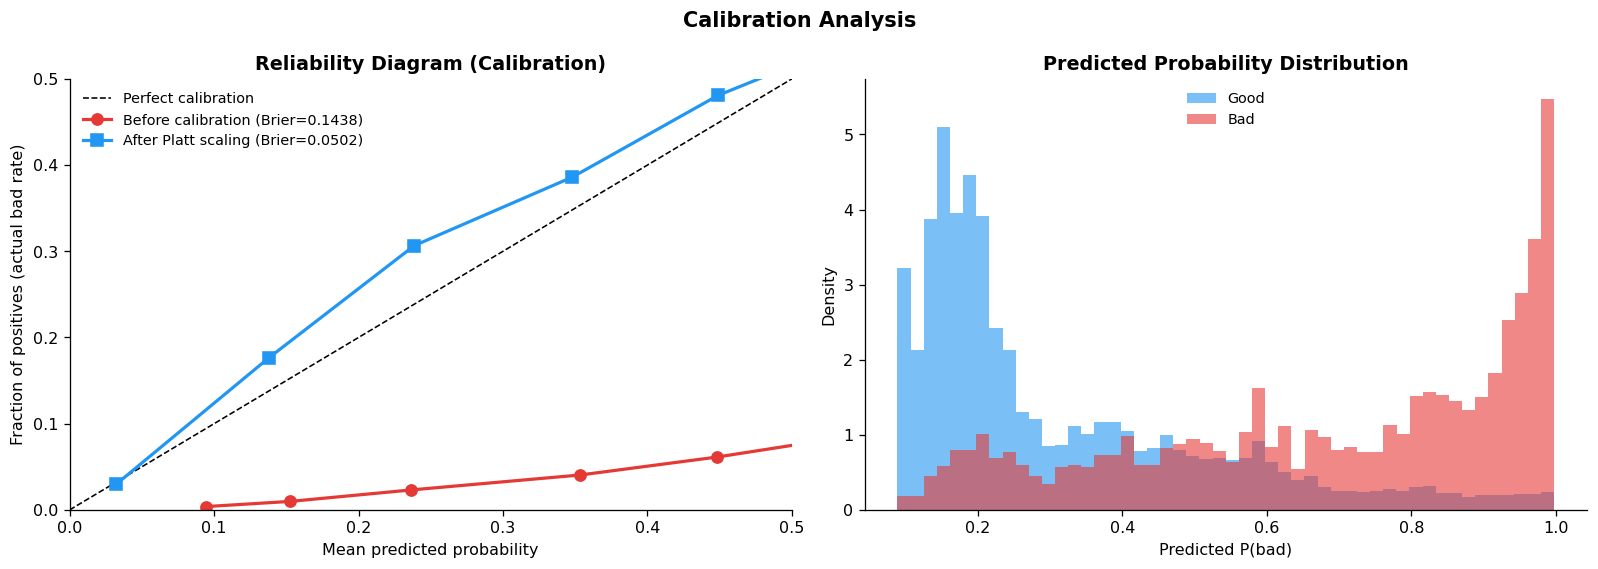

Brier score improvement after calibration: 65.1%
✓ Platt scaling cải thiện calibration — dùng calibrated_lr cho production


In [14]:
# ── Calibration trước và sau Platt Scaling ───────────────────────────────────
calibrated_lr = CalibratedClassifierCV(lr_model, method="sigmoid", cv="prefit")
calibrated_lr.fit(X_train, y_train)
y_prob_cal = calibrated_lr.predict_proba(X_test)[:, 1]

# Reliability curves
frac_pos_raw, mean_pred_raw = calibration_curve(y_test, y_prob_test, n_bins=10)
frac_pos_cal, mean_pred_cal = calibration_curve(y_test, y_prob_cal,  n_bins=10)

# Brier scores
brier_raw = brier_score_loss(y_test, y_prob_test)
brier_cal = brier_score_loss(y_test, y_prob_cal)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Reliability diagram ───────────────────────────────────────────────────────
axes[0].plot([0,1],[0,1], "k--", lw=1, label="Perfect calibration")
axes[0].plot(mean_pred_raw, frac_pos_raw, "o-",
             color=PALETTE["bad"],  lw=2, ms=7,
             label=f"Before calibration (Brier={brier_raw:.4f})")
axes[0].plot(mean_pred_cal, frac_pos_cal, "s-",
             color=PALETTE["good"], lw=2, ms=7,
             label=f"After Platt scaling (Brier={brier_cal:.4f})")
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Fraction of positives (actual bad rate)")
axes[0].set_title("Reliability Diagram (Calibration)")
axes[0].legend(fontsize=9, frameon=False)
axes[0].set_xlim(0, 0.5); axes[0].set_ylim(0, 0.5)

# ── Probability histogram ─────────────────────────────────────────────────────
axes[1].hist(y_prob_test[y_test==0], bins=50, alpha=0.6,
             color=PALETTE["good"], label="Good", density=True, edgecolor="none")
axes[1].hist(y_prob_test[y_test==1], bins=50, alpha=0.6,
             color=PALETTE["bad"],  label="Bad",  density=True, edgecolor="none")
axes[1].set_xlabel("Predicted P(bad)")
axes[1].set_ylabel("Density")
axes[1].set_title("Predicted Probability Distribution")
axes[1].legend(fontsize=9, frameon=False)

plt.suptitle("Calibration Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("14_calibration.png", bbox_inches="tight")
plt.show()

improvement = (brier_raw - brier_cal) / brier_raw * 100
print(f"Brier score improvement after calibration: {improvement:.1f}%")
if improvement > 0:
    print("✓ Platt scaling cải thiện calibration — dùng calibrated_lr cho production")
else:
    print("→ Calibration không cải thiện nhiều — dùng lr_model gốc cũng được")


#### Calibration Analysis

#### Reliability Diagram

Biểu đồ so sánh xác suất model dự đoán với bad rate thực tế:

| | Brier Score | Nhận xét |
|---|---|---|
| **Before calibration** (đỏ) | 0.1438 | Dự đoán **thấp hơn** thực tế rất nhiều |
| **After Platt scaling** (xanh) | 0.0502 | Gần với đường perfect hơn |
| **Cải thiện** | **65.1%** | ✅ Platt scaling hiệu quả rõ rệt |

> **Brier Score** đo sai số giữa xác suất dự đoán và nhãn thực — càng thấp càng tốt.

---

#### Vấn đề trước calibration

Đường đỏ nằm **rất thấp so với đường diagonal** → model đang **underestimate** xác suất vỡ nợ:

```
Model nói: "khách này 20% khả năng vỡ nợ"
Thực tế:   khách này 35% khả năng vỡ nợ  ← nguy hiểm!
```

Nếu dùng trực tiếp để tính expected loss hay định giá rủi ro sẽ **sai lệch nghiêm trọng**.

---

#### Sau Platt Scaling

Đường xanh **bám sát đường diagonal** hơn nhiều → xác suất dự đoán đáng tin cậy hơn để:
- Tính **Expected Loss**
- **Định giá** khoản vay theo rủi ro
- Ra quyết định dựa trên **ngưỡng xác suất** thay vì score

---

#### Predicted Probability Distribution

- Nhóm **Good** (xanh) tập trung ở vùng **P(bad) thấp** (~0.1–0.2) ✅
- Nhóm **Bad** (đỏ) tập trung ở vùng **P(bad) cao** (~0.8–1.0) ✅
- Hai phân phối tách biệt rõ → model **phân biệt tốt** Good vs Bad

---

#### Kết luận

Dùng **`calibrated_lr` cho production** thay vì model gốc vì:
- Brier score giảm 65.1% sau Platt scaling
- Xác suất dự đoán phản ánh đúng rủi ro thực tế hơn

#### 3. Threshold Optimization — Precision / Recall

Với imbalanced dataset (bad rate 6.7%), F1-score và Precision-Recall  
quan trọng hơn Accuracy. Ta tìm threshold tối ưu theo **F1-score**.

- **Precision** = trong số bị reject, bao nhiêu % thực sự là Bad?
- **Recall** = trong số Bad thực, bao nhiêu % bị model bắt được?
- **F1** = harmonic mean của Precision và Recall

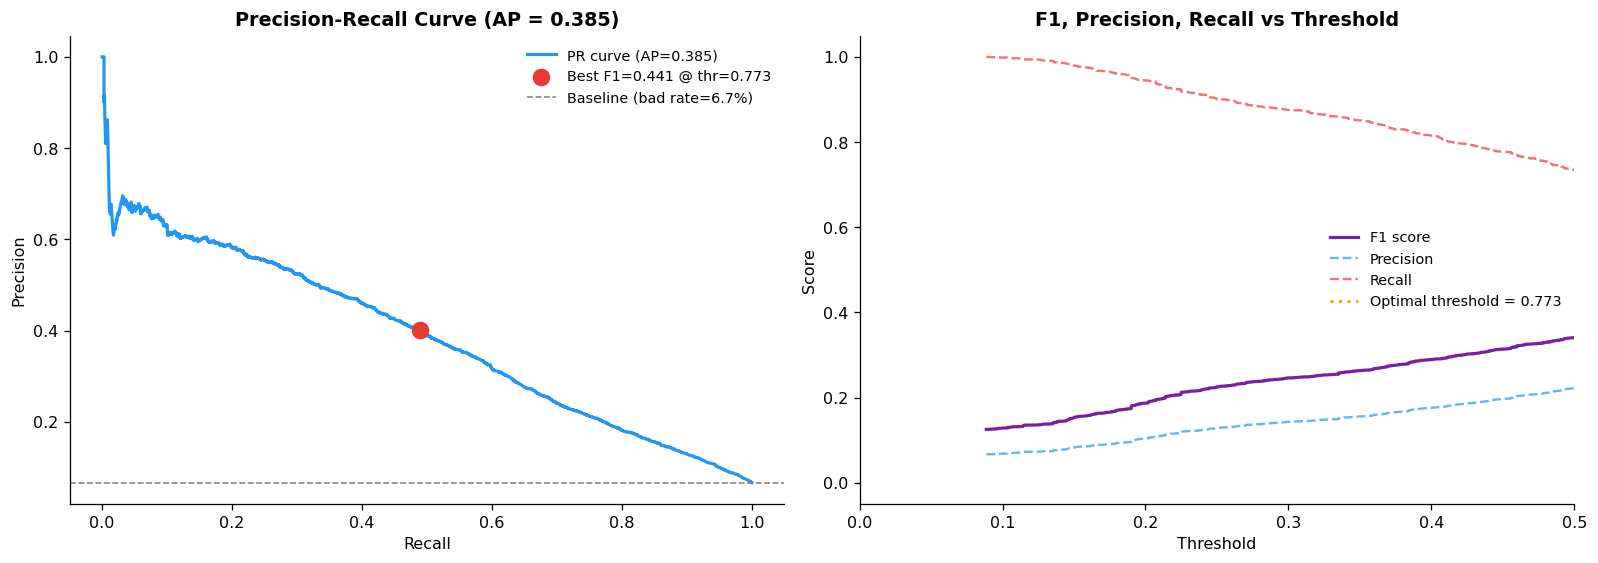


Optimal threshold: 0.7726  |  F1: 0.4409

Confusion Matrix (threshold = 0.773):
  TN=39,798  FP=2,194
  FN=1,537  TP=1,471

              precision    recall  f1-score   support

        Good       0.96      0.95      0.96     41992
         Bad       0.40      0.49      0.44      3008

    accuracy                           0.92     45000
   macro avg       0.68      0.72      0.70     45000
weighted avg       0.93      0.92      0.92     45000



In [19]:
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_prob_test)
ap_score = average_precision_score(y_test, y_prob_test)

# F1 tại mỗi threshold
f1_scores = np.where(
    (precision[:-1] + recall[:-1]) > 0,
    2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1]),
    0
)
best_idx = np.argmax(f1_scores)
best_thr = pr_thresholds[best_idx]
best_f1  = f1_scores[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── PR Curve ──────────────────────────────────────────────────────────────────
axes[0].plot(recall, precision, color=PALETTE["good"], lw=2,
             label=f"PR curve (AP={ap_score:.3f})")
axes[0].scatter(recall[best_idx], precision[best_idx],
                color=PALETTE["bad"], s=100, zorder=5,
                label=f"Best F1={best_f1:.3f} @ thr={best_thr:.3f}")
axes[0].axhline(y_test.mean(), color="gray", linestyle="--", lw=1,
                label=f"Baseline (bad rate={y_test.mean()*100:.1f}%)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title(f"Precision-Recall Curve (AP = {ap_score:.3f})")
axes[0].legend(fontsize=9, frameon=False)

# ── F1 vs Threshold ───────────────────────────────────────────────────────────
axes[1].plot(pr_thresholds, f1_scores, color="#7B1FA2", lw=2, label="F1 score")
axes[1].plot(pr_thresholds, precision[:-1], color=PALETTE["good"],
             lw=1.5, linestyle="--", alpha=0.7, label="Precision")
axes[1].plot(pr_thresholds, recall[:-1],    color=PALETTE["bad"],
             lw=1.5, linestyle="--", alpha=0.7, label="Recall")
axes[1].axvline(best_thr, color="orange", linestyle=":", lw=2,
                label=f"Optimal threshold = {best_thr:.3f}")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Score")
axes[1].set_title("F1, Precision, Recall vs Threshold")
axes[1].legend(fontsize=9, frameon=False)
axes[1].set_xlim(0, 0.5)

plt.tight_layout()
plt.savefig("15_precision_recall.png", bbox_inches="tight")
plt.show()

# Confusion matrix tại optimal threshold
y_pred_opt = (y_prob_test >= best_thr).astype(int)
cm = confusion_matrix(y_test, y_pred_opt)
print(f"\nOptimal threshold: {best_thr:.4f}  |  F1: {best_f1:.4f}")
print(f"\nConfusion Matrix (threshold = {best_thr:.3f}):")
print(f"  TN={cm[0,0]:,}  FP={cm[0,1]:,}")
print(f"  FN={cm[1,0]:,}  TP={cm[1,1]:,}")
print()
print(classification_report(y_test, y_pred_opt, target_names=["Good","Bad"]))


#### Precision-Recall & Threshold Analysis

#### Precision-Recall Curve (AP = 0.385)

- **AP = 0.385** — cao hơn nhiều so với baseline bad rate 6.7% → model **phân biệt tốt**
- **Best F1 = 0.441 tại threshold = 0.773** (chấm đỏ)
- Precision giảm dần khi Recall tăng → trade-off điển hình của imbalanced data

---

#### Confusion Matrix (threshold = 0.773)

```
                 Dự đoán Good    Dự đoán Bad
Thực tế Good      TN=39,798       FP=2,194
Thực tế Bad       FN=1,537        TP=1,471
```

| | Precision | Recall | F1 |
|---|---|---|---|
| **Good** | 0.96 | 0.95 | 0.96 |
| **Bad** | 0.40 | 0.49 | 0.44 |
| Accuracy | | | 0.92 |

---

#### Phân tích kết quả

**Với nhóm Good:**
- Precision 0.96, Recall 0.95 → nhận diện khách tốt **rất chính xác** ✅

**Với nhóm Bad:**
- Recall = 0.49 → model chỉ bắt được **49% khách Bad** thực tế
- FN = 1,537 → còn **1,537 khách Bad bị approve nhầm** ⚠️
- Đây là hệ quả tất yếu của **imbalanced data** (93% Good / 7% Bad)

---

#### F1, Precision, Recall vs Threshold

- **Recall** (đỏ) giảm khi threshold tăng → threshold cao = từ chối nhiều hơn
- **Precision** (xanh) tăng khi threshold tăng → ít approve nhầm Bad hơn
- **F1** (tím) đạt tối ưu tại threshold = **0.773**

---

#### Lưu ý quan trọng

Threshold 0.773 là tối ưu theo **F1**, nhưng trong thực tế tín dụng nên cân nhắc:

| Ưu tiên | Threshold | Hệ quả |
|---|---|---|
| Giảm FN (bắt nhiều Bad hơn) | **Thấp hơn** 0.773 | Từ chối thêm khách tốt |
| Giảm FP (ít approve nhầm) | **Cao hơn** 0.773 | Bỏ lỡ nhiều khách Bad |

> Quyết định cuối cùng phụ thuộc vào **chi phí của FN vs FP** trong bối cảnh kinh doanh cụ thể.

#### 4. Population Stability Index (PSI)

PSI đo lường **drift** của phân phối score giữa thời điểm train và deploy (hoặc giữa các kỳ).  
Trong thực tế: so sánh score distribution của train set (baseline) vs test set (recent).

$$PSI = \sum_{i} (\%Actual_i - \%Expected_i) \times \ln\left(\frac{\%Actual_i}{\%Expected_i}\right)$$

| PSI | Kết luận |
|---|---|
| < 0.10 | Ổn định — không cần action |
| 0.10 – 0.25 | Theo dõi thêm |
| > 0.25 | Drift nghiêm trọng — cần retrain |

PSI (train vs test): 0.0003
Status: ✓ Ổn định — model stable

Score Band  Expected %  Actual %    PSI
   336–488      9.7500    9.5500 0.0000
   488–511      9.8600    9.7900 0.0000
   511–526     10.0600   10.1800 0.0000
   526–538     10.0900   10.0600 0.0000
   538–550      9.9000   10.1800 0.0001
   550–555      9.6400    9.3100 0.0001
   555–560     10.6700   10.5500 0.0000
   560–566      9.4100    9.5200 0.0000
   566–571     10.0600   10.2600 0.0000
   571–583     10.5600   10.6000 0.0000

✓ Saved: psi_report.csv


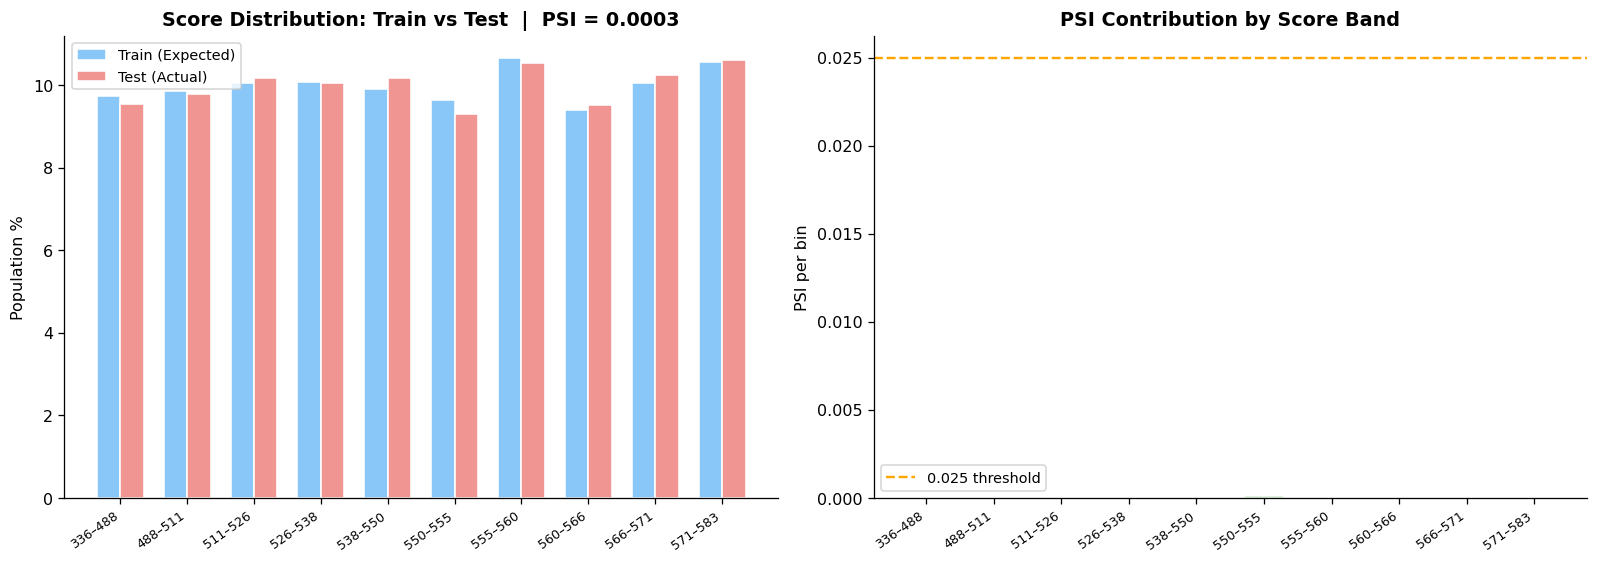

In [23]:
def compute_psi(expected: np.ndarray, actual: np.ndarray,
                n_bins: int = 10) -> tuple[float, pd.DataFrame]:
    """
    Tính PSI giữa expected (train) và actual (test) score distributions.
    
    Returns
    -------
    psi_total : float
    psi_table : pd.DataFrame — chi tiết từng bin
    """
    # Tạo bins dựa trên expected distribution
    breakpoints = np.percentile(expected, np.linspace(0, 100, n_bins + 1))
    breakpoints  = np.unique(breakpoints)  # loại duplicate

    exp_counts = np.histogram(expected, bins=breakpoints)[0]
    act_counts = np.histogram(actual,   bins=breakpoints)[0]

    exp_pct = exp_counts / len(expected)
    act_pct = act_counts / len(actual)

    # Tránh log(0)
    eps = 1e-6
    exp_pct = np.where(exp_pct == 0, eps, exp_pct)
    act_pct = np.where(act_pct == 0, eps, act_pct)

    psi_bins = (act_pct - exp_pct) * np.log(act_pct / exp_pct)
    psi_total = psi_bins.sum()

    labels = [f"{breakpoints[i]:.0f}–{breakpoints[i+1]:.0f}"
              for i in range(len(breakpoints)-1)]

    psi_table = pd.DataFrame({
        "Score Band":    labels,
        "Expected %":   (exp_pct * 100).round(2),
        "Actual %":     (act_pct * 100).round(2),
        "PSI":           psi_bins.round(5),
    })
    return psi_total, psi_table

# Score từ train/test (dùng index từ split)
train_idx, test_idx = train_test_split(
    score_all.index, test_size=0.3, random_state=42,
    stratify=score_all["target"]
)
score_train_vals = score_all.loc[train_idx, "score"].values
score_test_vals  = score_all.loc[test_idx,  "score"].values

psi_total, psi_table = compute_psi(score_train_vals, score_test_vals, n_bins=10)

print(f"PSI (train vs test): {psi_total:.4f}")
if psi_total < 0.10:
    status = "✓ Ổn định — model stable"
elif psi_total < 0.25:
    status = "⚠️  Theo dõi thêm — minor shift"
else:
    status = "✗ Drift nghiêm trọng — cần retrain"
print(f"Status: {status}")
print()
print(psi_table.to_string(index=False))

psi_table.to_csv("psi_report.csv", index=False)
print("\n✓ Saved: psi_report.csv")

# ── Visualize PSI ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(psi_table))
w = 0.35
axes[0].bar(x - w/2, psi_table["Expected %"], w, label="Train (Expected)",
            color=PALETTE["good"]+"88", edgecolor="white")
axes[0].bar(x + w/2, psi_table["Actual %"],   w, label="Test (Actual)",
            color=PALETTE["bad"]+"88",  edgecolor="white")
axes[0].set_xticks(x)
axes[0].set_xticklabels(psi_table["Score Band"], rotation=35, ha="right", fontsize=8)
axes[0].set_ylabel("Population %")
axes[0].set_title(f"Score Distribution: Train vs Test  |  PSI = {psi_total:.4f}")
axes[0].legend(fontsize=9)

axes[1].bar(x, psi_table["PSI"], color=[
    "#E53935" if v > 0.025 else "#FFB300" if v > 0.01 else "#66BB6A"
    for v in psi_table["PSI"]
], width=0.6, edgecolor="white")
axes[1].axhline(0.025, color="orange", linestyle="--", lw=1.5, label="0.025 threshold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(psi_table["Score Band"], rotation=35, ha="right", fontsize=8)
axes[1].set_ylabel("PSI per bin")
axes[1].set_title("PSI Contribution by Score Band")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig("16_psi_analysis.png", bbox_inches="tight")
plt.show()


#### PSI Analysis — Population Stability Index

#### PSI là gì?
PSI đo mức độ **thay đổi phân phối score** giữa tập Train và Test.
Nếu PSI thấp → phân phối ổn định → model **không bị drift**.

| PSI | Đánh giá |
|---|---|
| < 0.1 | ✅ Ổn định |
| 0.1 – 0.25 | ⚠️ Cần theo dõi |
| > 0.25 | ❌ Phân phối thay đổi đáng kể |

---

#### Kết quả

**PSI (train vs test) = 0.0003** → ✅ **Cực kỳ ổn định**

| Score Band | Expected % (Train) | Actual % (Test) | PSI |
|---|---|---|---|
| 336–488 | 9.75% | 9.55% | 0.0000 |
| 488–511 | 9.86% | 9.79% | 0.0000 |
| 511–526 | 10.06% | 10.18% | 0.0000 |
| 526–538 | 10.09% | 10.06% | 0.0000 |
| 538–550 | 9.90% | 10.18% | 0.0001 |
| 550–555 | 9.64% | 9.31% | 0.0001 |
| 555–560 | 10.67% | 10.55% | 0.0000 |
| 560–566 | 9.41% | 9.52% | 0.0000 |
| 566–571 | 10.06% | 10.26% | 0.0000 |
| 571–583 | 10.56% | 10.60% | 0.0000 |

---

#### Biểu đồ Score Distribution: Train vs Test

Cột xanh (Train) và đỏ (Test) **gần như bằng nhau** ở mọi score band
→ phân phối score **không thay đổi** khi chuyển từ train sang test.

---

#### PSI Contribution by Score Band

Tất cả các bin đều nằm **sát đường 0**, jauh dưới ngưỡng cảnh báo 0.025
→ không có score band nào bị drift đáng kể.

---

#### Kết luận

PSI = 0.0003 là kết quả **lý tưởng**, cho thấy:
- Dữ liệu train và test có **cùng phân phối**
- Stratified split đã hoạt động **đúng như kỳ vọng**
- Model sẽ **hoạt động ổn định** khi deploy trên dữ liệu mới có phân phối tương tự

#### 5. Gains & Lift Table

**Gains table** cho biết: nếu ta contact/review top X% khách hàng rủi ro nhất,  
ta capture được bao nhiêu % total Bad?

**Lift** = (% Bad captured) / (% Population reviewed) — Lift > 1 có nghĩa là tốt hơn random.

Gains & Lift Table (Test Set):
 Decile    N  N Bad  Bad Rate %  Cumulative N %  Cumulative Bad %   Lift
      1 4500   1627     36.1600         10.0000           54.1000 5.4090
      2 4500    497     11.0400         20.0000           70.6000 3.5310
      3 4500    292      6.4900         30.0000           80.3000 2.6770
      4 4500    200      4.4400         40.0000           87.0000 2.1740
      5 4500    132      2.9300         50.0000           91.4000 1.8270
      6 4500     92      2.0400         60.0000           94.4000 1.5740
      7 4500     54      1.2000         70.0000           96.2000 1.3740
      8 4500     57      1.2700         80.0000           98.1000 1.2260
      9 4500     34      0.7600         90.0000           99.2000 1.1030
     10 4500     23      0.5100        100.0000          100.0000 1.0000


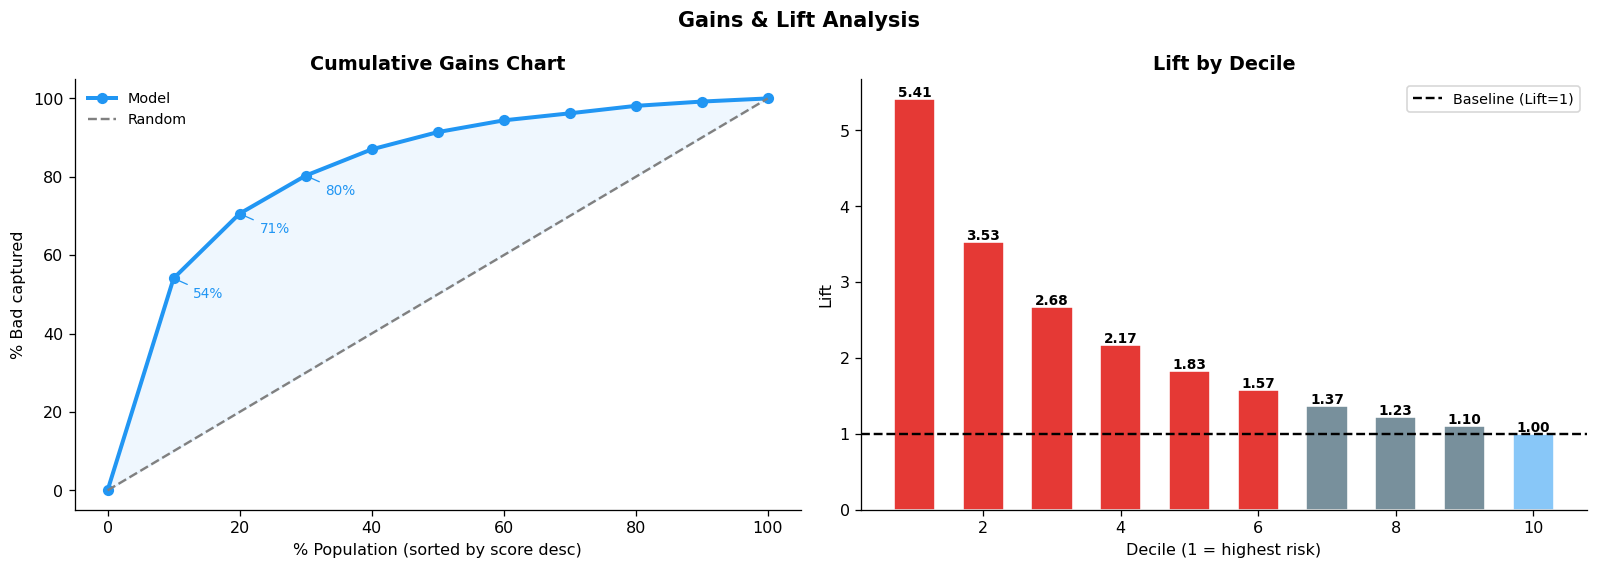


Key insight: Top 20% rủi ro nhất capture được 71% tổng số Bad


In [28]:
def gains_lift_table(y_true: np.ndarray, y_prob: np.ndarray,
                     n_deciles: int = 10) -> pd.DataFrame:
    """
    Xây dựng Gains & Lift table theo decile.
    Sắp xếp từ rủi ro cao nhất (decile 1) đến thấp nhất (decile 10).
    """
    df_gl = pd.DataFrame({"target": y_true, "prob": y_prob})
    df_gl = df_gl.sort_values("prob", ascending=False).reset_index(drop=True)
    df_gl["decile"] = pd.qcut(df_gl.index, n_deciles,
                               labels=range(1, n_deciles+1))

    total_bad  = y_true.sum()
    total_good = (1 - y_true).sum()
    total_n    = len(y_true)

    rows = []
    cum_bad = cum_good = cum_n = 0
    for d in range(1, n_deciles+1):
        grp = df_gl[df_gl["decile"] == d]
        n       = len(grp)
        n_bad   = grp["target"].sum()
        n_good  = n - n_bad
        cum_n   += n
        cum_bad += n_bad
        cum_good+= n_good
        rows.append({
            "Decile":          d,
            "N":               n,
            "N Bad":           int(n_bad),
            "Bad Rate %":      round(n_bad/n*100, 2) if n > 0 else 0,
            "Cumulative N %":  round(cum_n/total_n*100, 1),
            "Cumulative Bad %":round(cum_bad/total_bad*100, 1),
            "Lift":            round((cum_bad/total_bad) / (cum_n/total_n), 3),
        })
    return pd.DataFrame(rows)

gl_table = gains_lift_table(y_test.values, y_prob_test)
print("Gains & Lift Table (Test Set):")
print(gl_table.to_string(index=False))

# ── Visualize ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gains chart
axes[0].plot([0] + list(gl_table["Cumulative N %"]),
             [0] + list(gl_table["Cumulative Bad %"]),
             color=PALETTE["good"], lw=2.5, marker="o", ms=6,
             label="Model")
axes[0].plot([0, 100], [0, 100], color="gray", linestyle="--", lw=1.5, label="Random")
axes[0].fill_between(
    [0] + list(gl_table["Cumulative N %"]),
    [0] + list(gl_table["Cumulative Bad %"]),
    [0] + list(gl_table["Cumulative N %"]),
    alpha=0.07, color=PALETTE["good"]
)
# Annotate top 3 deciles
for _, row in gl_table.head(3).iterrows():
    axes[0].annotate(
        f"{row['Cumulative Bad %']:.0f}%",
        xy=(row["Cumulative N %"], row["Cumulative Bad %"]),
        xytext=(row["Cumulative N %"]+3, row["Cumulative Bad %"]-5),
        fontsize=8.5, color=PALETTE["good"],
        arrowprops=dict(arrowstyle="-", color=PALETTE["good"], lw=0.8),
    )
axes[0].set_xlabel("% Population (sorted by score desc)")
axes[0].set_ylabel("% Bad captured")
axes[0].set_title("Cumulative Gains Chart")
axes[0].legend(fontsize=9, frameon=False)

# Lift chart
axes[1].bar(gl_table["Decile"], gl_table["Lift"],
            color=[PALETTE["bad"] if l > 1.5 else
                   PALETTE["neutral"] if l > 1 else
                   PALETTE["good"] + "88"
                   for l in gl_table["Lift"]],
            width=0.6, edgecolor="white")
axes[1].axhline(1.0, color="black", linestyle="--", lw=1.5, label="Baseline (Lift=1)")
for i, row in gl_table.iterrows():
    axes[1].text(row["Decile"], row["Lift"] + 0.03,
                 f"{row['Lift']:.2f}", ha="center", fontsize=8.5, fontweight="bold")
axes[1].set_xlabel("Decile (1 = highest risk)")
axes[1].set_ylabel("Lift")
axes[1].set_title("Lift by Decile")
axes[1].legend(fontsize=9)

plt.suptitle("Gains & Lift Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("17_gains_lift.png", bbox_inches="tight")
plt.show()

print(f"\nKey insight: Top 20% rủi ro nhất capture được "
      f"{gl_table.loc[gl_table['Decile']==2, 'Cumulative Bad %'].values[0]:.0f}% "
      f"tổng số Bad")


#### Gains & Lift Analysis

#### Gains & Lift là gì?
Đánh giá **hiệu quả của model so với chọn ngẫu nhiên** khi ta chỉ xem xét
một phần dân số — ví dụ: nếu chỉ review 20% khách rủi ro nhất, bắt được bao nhiêu % Bad?

---

#### Gains & Lift Table

| Decile | N Bad | Bad Rate % | Cumulative Bad % | Lift |
|---|---|---|---|---|
| 1 (rủi ro cao nhất) | 1,627 | 36.16% | 54.10% | **5.41** |
| 2 | 497 | 11.04% | 70.60% | 3.53 |
| 3 | 292 | 6.49% | 80.30% | 2.68 |
| 4 | 200 | 4.44% | 87.00% | 2.17 |
| 5 | 132 | 2.93% | 91.40% | 1.83 |
| 6 | 92 | 2.04% | 94.40% | 1.57 |
| 7 | 54 | 1.20% | 96.20% | 1.37 |
| 8 | 57 | 1.27% | 98.10% | 1.23 |
| 9 | 34 | 0.76% | 99.20% | 1.10 |
| 10 (rủi ro thấp nhất) | 23 | 0.51% | 100.00% | 1.00 |

---

#### Cumulative Gains Chart

Đường model (xanh) **cong lên xa đường random** (đứt) → model tập trung
Bad vào các decile đầu rất hiệu quả:

- Top **10%** → bắt được **54%** tổng số Bad
- Top **20%** → bắt được **71%** tổng số Bad ⭐
- Top **30%** → bắt được **80%** tổng số Bad

> **Key insight:** Chỉ cần review **20% khách rủi ro nhất**, model đã
> bắt được **71% tổng số Bad** — thay vì phải review toàn bộ.

---

#### Lift by Decile

- **Decile 1: Lift = 5.41** → nhóm rủi ro cao nhất có bad rate **gấp 5.41 lần**
  so với chọn ngẫu nhiên
- Lift giảm đều từ 5.41 → 1.00 → **đơn điệu, nhất quán** ✅
- Decile 10: Lift = 1.00 → bằng baseline, đúng như kỳ vọng

---

#### Kết luận

Model phân tách rủi ro **rất hiệu quả**. Trong thực tế có thể ứng dụng để:
- **Ưu tiên review** hồ sơ theo thứ tự decile từ cao xuống thấp
- **Tối ưu nguồn lực** thẩm định — chỉ cần xem top 20–30% là kiểm soát được phần lớn rủi ro
- **Định giá phân tầng** theo mức độ rủi ro của từng decile

#### 6. Backtesting — Basel Traffic Light Test

Basel II yêu cầu **backtesting** hàng năm: so sánh số lượng exceptions  
(predicted good nhưng thực tế default) với ngưỡng cho phép.

| Vùng | Exceptions / 250 obs | Ý nghĩa |
|---|---|---|
| Xanh | 0–4 | Model tốt |
| Vàng | 5–9 | Cần theo dõi |
| Đỏ | ≥ 10 | Model có vấn đề — điều tra ngay |

*250 là số ngày giao dịch trong 1 năm (convention của Basel cho market risk,  
áp dụng tương tự cho credit backtesting theo tỷ lệ)*

## Basel II & Mối liên hệ với Scorecard

### Tổng quan
Basel II là bộ tiêu chuẩn quốc tế về **quản lý rủi ro và vốn** cho các ngân hàng,
do Ủy ban Basel ban hành năm 2004. Scorecard model được xây dựng trong notebook này
là một phần của **PD model** theo chuẩn Basel II.

---

### 3 Trụ cột chính

| Pillar | Nội dung |
|---|---|
| **Pillar 1** | Yêu cầu vốn tối thiểu cho Credit, Market & Operational Risk |
| **Pillar 2** | Giám sát nội bộ (ICAAP) |
| **Pillar 3** | Công khai thông tin ra thị trường |

---

### IRB Approach & Scorecard

Basel II cho phép ngân hàng dùng **IRB Approach** (Internal Ratings-Based)
— tự xây model nội bộ để tính 3 chỉ số:

| Chỉ số | Tên đầy đủ | Ý nghĩa |
|---|---|---|
| **PD** | Probability of Default | Xác suất khách hàng vỡ nợ → *output của scorecard* |
| **LGD** | Loss Given Default | % tổn thất khi khách vỡ nợ |
| **EAD** | Exposure at Default | Dư nợ tại thời điểm vỡ nợ |

$$\text{Expected Loss} = PD \times LGD \times EAD$$

---

### Basel I → II → III

| Phiên bản | Năm | Điểm mới |
|---|---|---|
| Basel I | 1988 | Chỉ có credit risk, quy tắc đơn giản |
| **Basel II** | 2004 | Thêm market & operational risk, cho phép model nội bộ (IRB) |
| Basel III | 2010 | Thêm yêu cầu thanh khoản sau khủng hoảng 2008 |

> Scorecard model trong notebook này ước tính **PD** — đầu vào quan trọng nhất
> trong công thức Expected Loss theo chuẩn Basel II.

In [34]:
def basel_traffic_light(y_true: np.ndarray, y_prob: np.ndarray,
                        threshold: float, n_obs: int = 250) -> dict:
    """
    Basel Traffic Light test cho credit model.
    Exception = model predict Good (prob < threshold) nhưng thực tế Bad.
    
    Parameters
    ----------
    threshold : float — ngưỡng phân loại Good/Bad
    n_obs     : int   — số observations trong backtest window (default 250)
    """
    from scipy.stats import binom

    # Sample n_obs từ test set
    np.random.seed(42)
    idx = np.random.choice(len(y_true), min(n_obs, len(y_true)), replace=False)
    y_s = y_true[idx]
    p_s = y_prob[idx]

    predicted_good = p_s < threshold
    exceptions = int((predicted_good & (y_s == 1)).sum())
    n_predicted_good = predicted_good.sum()

    # P-value: probability of getting >= exceptions under null (model correct)
    # Null: P(exception) = actual bad rate among predicted good
    actual_bad_rate = y_s[predicted_good].mean() if predicted_good.sum() > 0 else 0
    expected_bad_rate = y_true.mean()
    p_value = 1 - binom.cdf(exceptions - 1, n_predicted_good, expected_bad_rate)

    # Traffic light
    exception_rate = exceptions / n_obs
    if exceptions <= 4:
        zone, color = "GREEN",  "#4CAF50"
    elif exceptions <= 9:
        zone, color = "YELLOW", "#FFC107"
    else:
        zone, color = "RED",    "#F44336"

    return {
        "n_obs":            n_obs,
        "n_predicted_good": int(n_predicted_good),
        "exceptions":       exceptions,
        "exception_rate":   round(exception_rate * 100, 2),
        "zone":             zone,
        "color":            color,
        "p_value":          round(p_value, 4),
    }

# Test tại nhiều threshold
thresholds_test = [0.05, 0.07, 0.10, 0.15, 0.20]
print("Basel Traffic Light Results:")
print("─" * 65)
print(f"{'Threshold':>10} {'N Good':>8} {'Exceptions':>11} {'Rate':>7} {'Zone':>8} {'p-value':>9}")
print("─" * 65)

results_btl = {}
for thr in thresholds_test:
    r = basel_traffic_light(y_test.values, y_prob_test, threshold=thr)
    results_btl[thr] = r
    print(f"{thr:>10.2f} {r['n_predicted_good']:>8,} {r['exceptions']:>11} "
          f"{r['exception_rate']:>6.2f}% {r['zone']:>8}  {r['p_value']:>9.4f}")

print("─" * 65)
print()

# Recommended threshold
rec_thr = None
for thr, r in results_btl.items():
    if r["zone"] == "GREEN":
        rec_thr = thr
        break
if rec_thr:
    print(f"✓ Recommended threshold: {rec_thr} → Zone {results_btl[rec_thr]['zone']}")


Basel Traffic Light Results:
─────────────────────────────────────────────────────────────────
 Threshold   N Good  Exceptions    Rate     Zone   p-value
─────────────────────────────────────────────────────────────────
      0.05        0           0   0.00%    GREEN     1.0000
      0.07        0           0   0.00%    GREEN     1.0000
      0.10        8           0   0.00%    GREEN     1.0000
      0.15       64           2   0.80%    GREEN     0.9333
      0.20      107           2   0.80%    GREEN     0.9947
─────────────────────────────────────────────────────────────────

✓ Recommended threshold: 0.05 → Zone GREEN


#### 7. Top Reason Codes — Giải thích từng quyết định

Reason codes là **bắt buộc theo luật** ở nhiều quốc gia (ECOA, GDPR Article 22).  
Ngân hàng phải gửi thư từ chối kèm 4–5 lý do cụ thể tại sao đơn vay bị reject.

Cách tính: với mỗi khách hàng, so sánh điểm của bin họ đang ở  
với điểm tối đa có thể đạt được của từng biến → phần thiếu nhiều nhất = reason code #1.


In [46]:
# Rebuild scorecard card object từ model + bins
import scorecardpy as sc

card = sc.scorecard(
    bins_final,
    lr_model,
    xcolumns=WOE_COLS_FINAL,
    points0=600,
    odds0=1/19,
    pdo=20,
    basepoints_eq0=False,
)
print("✓ card rebuilt")

✓ card rebuilt


In [48]:
import scorecardpy as sc

def get_reason_codes(customer_data: pd.Series, card: dict,
                     bins: dict, top_n: int = 5) -> pd.DataFrame:
    """
    Tính reason codes cho 1 khách hàng.
    
    Parameters
    ----------
    customer_data : pd.Series — 1 hàng từ raw data (KHÔNG phải WOE)
    card          : dict      — scorecard từ sc.scorecard()
    bins          : dict      — bins từ sc.woebin()
    top_n         : int       — số reason codes muốn trả về
    
    Returns
    -------
    DataFrame với cột: variable, customer_bin, customer_points,
                       max_points, points_gap, rank
    """
    rows = []
    for var, card_tbl in card.items():
        if var == "basepoints":
            continue
        raw_var = var.replace("_woe", "")
        if raw_var not in customer_data.index:
            continue

        val = customer_data[raw_var]
        bin_tbl = bins.get(raw_var, None)
        if bin_tbl is None:
            continue

        # Tìm bin của khách hàng
        customer_points = None
        customer_bin    = "unknown"
        for _, row in bin_tbl.iterrows():
            bin_str = str(row["bin"])
            # Parse bin range
            try:
                if "," in bin_str:
                    lo = float(bin_str.split(",")[0].replace("[","").replace("(","").replace("-inf","-999999"))
                    hi = float(bin_str.split(",")[1].replace(")","").replace("]","").replace("inf","999999"))
                    if lo <= val < hi:
                        customer_bin = bin_str
                        pts_match = card_tbl[card_tbl["bin"] == bin_str]
                        if not pts_match.empty:
                            customer_points = pts_match["points"].values[0]
                        break
            except Exception:
                continue

        max_points = card_tbl["points"].max()
        if customer_points is None:
            customer_points = card_tbl["points"].min()

        rows.append({
            "Variable":         raw_var,
            "Customer bin":     customer_bin,
            "Customer points":  round(customer_points, 1),
            "Max points":       round(max_points, 1),
            "Points gap":       round(max_points - customer_points, 1),
        })

    df_rc = (pd.DataFrame(rows)
               .sort_values("Points gap", ascending=False)
               .reset_index(drop=True))
    df_rc.insert(0, "Rank", range(1, len(df_rc)+1))
    return df_rc.head(top_n)

# ── Demo: lấy 3 khách hàng mẫu ───────────────────────────────────────────────
with open("../Logistic regression/model_lr.pkl", "rb") as f: lr_model_rc = pickle.load(f)

# Load scorecard
df_raw_clean = pd.read_csv("../EDA Cleaning/cs_training_cleaned.csv")

# Reload card (cần chạy lại sc.scorecard nếu chưa có trong memory)
# Nếu có lỗi ở đây, chạy lại Cell 7 của Bước 3 trước
try:
    card  # check if exists
    print("✓ Card loaded from memory")
except NameError:
    print("⚠️  Cần reload card — chạy lại Cell 7 của Bước 3 trước")

# Lấy 3 khách hàng bị reject (score thấp)
rejected = score_all[score_all["score"] < 550].head(3)
print(f"\nDemo reason codes cho 3 khách hàng bị reject (score < 550):")
print("=" * 60)
for i, (idx, row) in enumerate(rejected.iterrows()):
    customer = df_raw_clean.iloc[idx]
    print(f"\n--- Khách hàng #{i+1} | Score = {row['score']:.0f} | Target = {row['target']} ---")
    rc = get_reason_codes(customer, card, bins_final, top_n=5)
    print(rc[["Rank","Variable","Customer bin","Customer points","Max points","Points gap"]].to_string(index=False))


✓ Card loaded from memory

Demo reason codes cho 3 khách hàng bị reject (score < 550):

--- Khách hàng #1 | Score = 482 | Target = 1 ---
 Rank       Variable Customer bin  Customer points  Max points  Points gap
    1 revolving_util    [0.6,0.9)         -15.0000     22.0000     37.0000
    2 past_due_30_59    [1.0,3.0)         -19.0000     10.0000     29.0000
    3            age  [35.0,50.0)          -4.0000     14.0000     18.0000
    4     debt_ratio    [0.5,inf)          -6.0000      5.0000     11.0000
    5     dependents    [2.0,3.0)          -2.0000      2.0000      4.0000

--- Khách hàng #2 | Score = 505 | Target = 0 ---
 Rank          Variable  Customer bin  Customer points  Max points  Points gap
    1    revolving_util     [0.9,inf)         -27.0000     22.0000     49.0000
    2               age   [35.0,50.0)          -4.0000     14.0000     18.0000
    3    monthly_income [-inf,5000.0)          -2.0000      4.0000      6.0000
    4        dependents     [1.0,2.0)          

## Reason Codes — Phân tích khách hàng bị Reject (Score < 550)

### Reason Codes là gì?
Với mỗi khách hàng bị từ chối, **Reason Codes** chỉ ra những biến nào
đang **kéo điểm xuống nhiều nhất** so với mức tối đa có thể đạt được.

```
Points gap = Max points - Customer points
```
Gap càng lớn → biến đó càng là nguyên nhân chính khiến score thấp.

---

### Khách hàng #1 | Score = 482 | Target = 1 (Bad) ✅ Từ chối đúng

| Rank | Biến | Bin | Điểm hiện tại | Điểm tối đa | Gap |
|---|---|---|---|---|---|
| 1 | `revolving_util` | [0.6, 0.9) | -15 | 22 | **37** |
| 2 | `past_due_30_59` | [1.0, 3.0) | -19 | 10 | **29** |
| 3 | `age` | [35.0, 50.0) | -4 | 14 | 18 |
| 4 | `debt_ratio` | [0.5, inf) | -6 | 5 | 11 |
| 5 | `dependents` | [2.0, 3.0) | -2 | 2 | 4 |

**Nhận xét:** Đây là khách Bad thật sự. Tỷ lệ sử dụng hạn mức tín dụng cao
(0.6–0.9) và có lịch sử trễ hạn 30–59 ngày — hai yếu tố rủi ro nghiêm trọng nhất.

---

### Khách hàng #2 | Score = 505 | Target = 0 (Good) ⚠️ Từ chối nhầm

| Rank | Biến | Bin | Điểm hiện tại | Điểm tối đa | Gap |
|---|---|---|---|---|---|
| 1 | `revolving_util` | [0.9, inf) | -27 | 22 | **49** |
| 2 | `age` | [35.0, 50.0) | -4 | 14 | 18 |
| 3 | `monthly_income` | [-inf, 5000) | -2 | 4 | 6 |
| 4 | `dependents` | [1.0, 2.0) | -1 | 2 | 3 |
| 5 | `real_estate_loans` | [-inf, 1.0) | -1 | 1 | 2 |

**Nhận xét:** Đây là khách Good nhưng bị từ chối do `revolving_util` cực cao (≥0.9)
kéo điểm xuống 49 điểm. Đây là trường hợp **false negative** — khách tốt bị loại
vì một chỉ số duy nhất quá xấu.

---

### Khách hàng #3 | Score = 449 | Target = 0 (Good) ⚠️ Từ chối nhầm

| Rank | Biến | Bin | Điểm hiện tại | Điểm tối đa | Gap |
|---|---|---|---|---|---|
| 1 | `late_90_days` | [1.0, 2.0) | -35 | 7 | **42** |
| 2 | `revolving_util` | [0.6, 0.9) | -15 | 22 | 37 |
| 3 | `past_due_30_59` | [1.0, 3.0) | -19 | 10 | 29 |
| 4 | `age` | [35.0, 50.0) | -4 | 14 | 18 |
| 5 | `monthly_income` | [-inf, 5000) | -2 | 4 | 6 |

**Nhận xét:** Khách Good nhưng có lịch sử trễ hạn >90 ngày — biến có
penalty nặng nhất trong scorecard. Dù là Good hiện tại, lịch sử tín dụng
xấu trong quá khứ khiến score rất thấp (449).

---

### Tổng kết

| | Khách #1 | Khách #2 | Khách #3 |
|---|---|---|---|
| Score | 482 | 505 | 449 |
| Target thực tế | Bad | **Good** | **Good** |
| Quyết định | ✅ Đúng | ⚠️ Nhầm | ⚠️ Nhầm |
| Nguyên nhân chính | revolving_util + past_due | revolving_util cao | late_90_days |

> Khách #2 và #3 là ví dụ điển hình của **FN (False Negative)** —
> từ chối khách tốt. Nếu muốn giảm FN, có thể hạ cutoff xuống dưới 500,
> nhưng sẽ đánh đổi bằng việc duyệt thêm khách Bad.

#### 8. Validation Report — Summary Dashboard

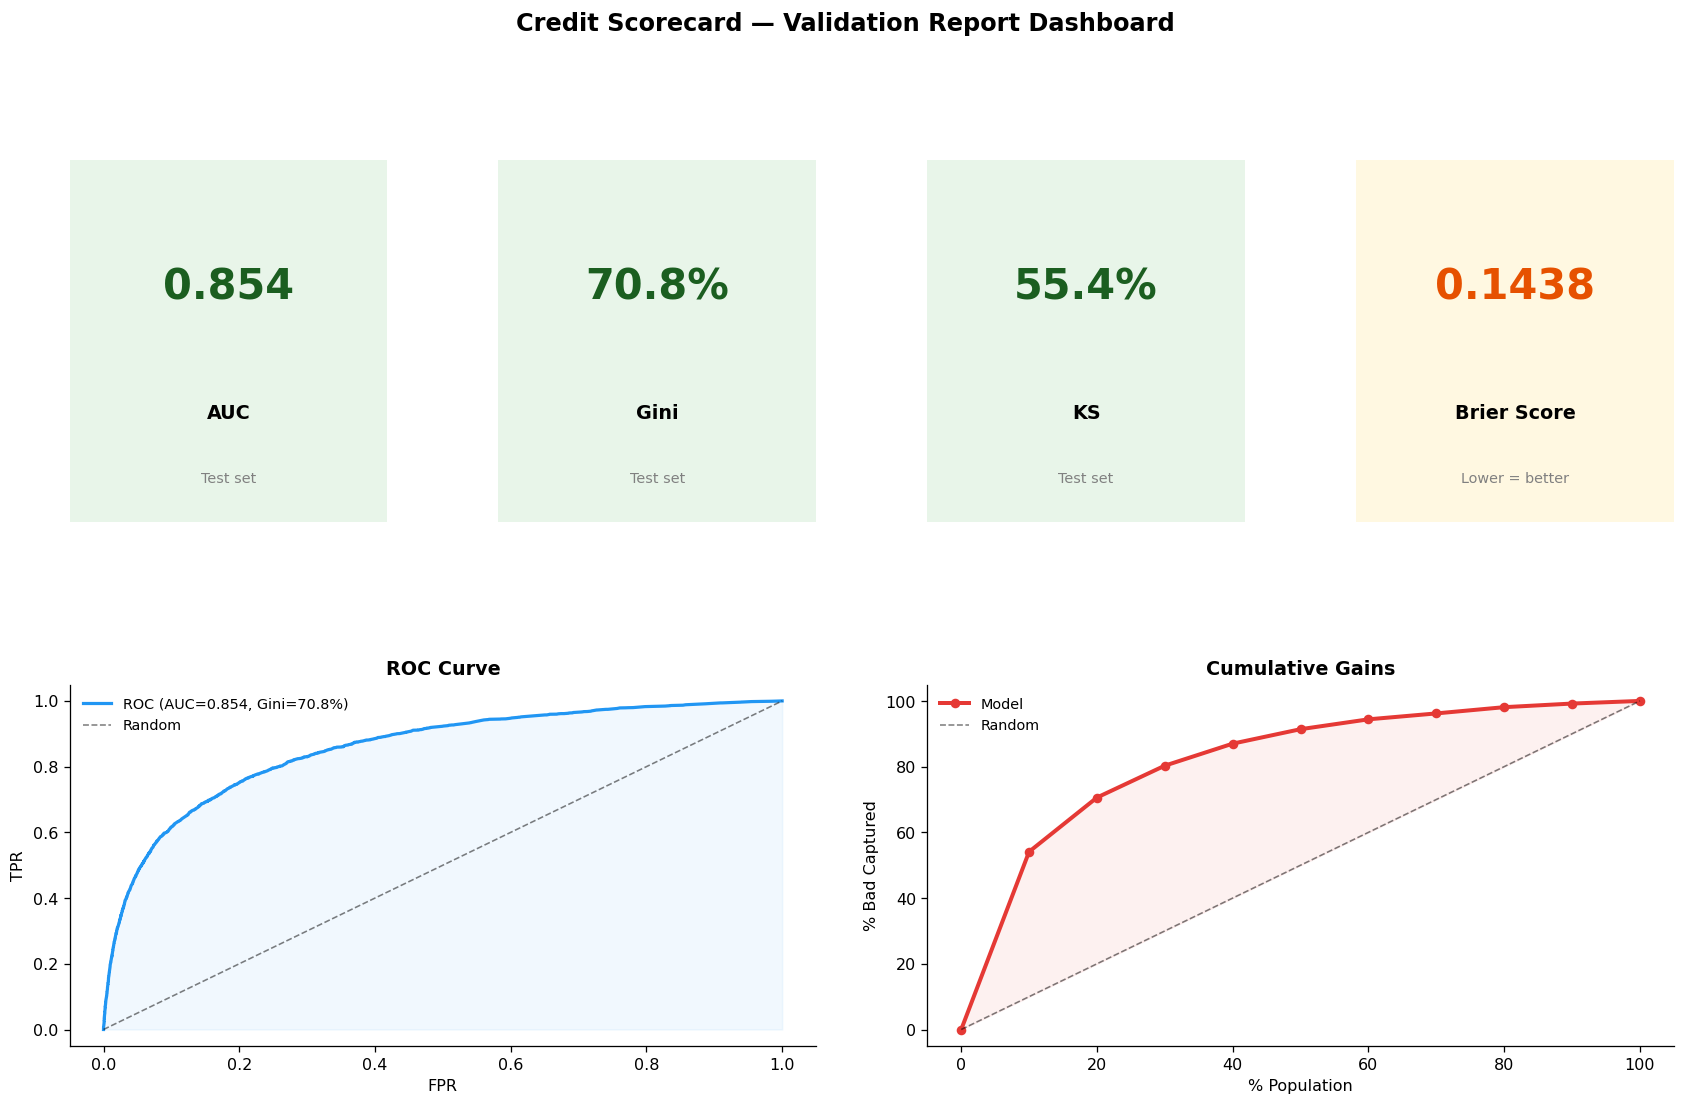

✓ Saved: 18_validation_dashboard.png


In [54]:
fig = plt.figure(figsize=(18, 10))
gs  = gridspec.GridSpec(2, 4, figure=fig, hspace=0.45, wspace=0.35)

auc_train = roc_auc_score(y_train, y_prob_train)
gini_test = 2 * auc_test - 1
fpr_c, tpr_c, _ = roc_curve(y_test, y_prob_test)
ks_stat = (tpr_c - fpr_c).max()

# ── 1. Metric cards (top row) ─────────────────────────────────────────────────
metrics = [
    ("AUC",         f"{auc_test:.3f}",         "Test set",      auc_test > 0.75),
    ("Gini",        f"{gini_test*100:.1f}%",    "Test set",      gini_test > 0.5),
    ("KS",          f"{ks_stat*100:.1f}%",      "Test set",      ks_stat > 0.4),
    ("Brier Score", f"{brier_raw:.4f}",         "Lower = better",brier_raw < 0.06),
]
for i, (name, val, sub, is_good) in enumerate(metrics):
    ax = fig.add_subplot(gs[0, i])
    color = "#E8F5E9" if is_good else "#FFF8E1"
    ax.set_facecolor(color)
    ax.text(0.5, 0.65, val, ha="center", va="center",
            fontsize=26, fontweight="bold", transform=ax.transAxes,
            color="#1B5E20" if is_good else "#E65100")
    ax.text(0.5, 0.30, name, ha="center", va="center",
            fontsize=12, fontweight="bold", transform=ax.transAxes)
    ax.text(0.5, 0.12, sub, ha="center", va="center",
            fontsize=9, color="gray", transform=ax.transAxes)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# ── 2. ROC Curve ──────────────────────────────────────────────────────────────
ax_roc = fig.add_subplot(gs[1, 0:2])
ax_roc.plot(fpr_c, tpr_c, color=PALETTE["good"], lw=2,
            label=f"ROC (AUC={auc_test:.3f}, Gini={gini_test*100:.1f}%)")
ax_roc.plot([0,1],[0,1], "k--", lw=1, alpha=0.5, label="Random")
ax_roc.fill_between(fpr_c, tpr_c, alpha=0.06, color=PALETTE["good"])
ax_roc.set_xlabel("FPR"); ax_roc.set_ylabel("TPR")
ax_roc.set_title("ROC Curve")
ax_roc.legend(fontsize=9, frameon=False)

# ── 3. Gains Chart ────────────────────────────────────────────────────────────
ax_gains = fig.add_subplot(gs[1, 2:4])
ax_gains.plot([0]+list(gl_table["Cumulative N %"]),
              [0]+list(gl_table["Cumulative Bad %"]),
              color=PALETTE["bad"], lw=2.5, marker="o", ms=5, label="Model")
ax_gains.plot([0,100],[0,100],"k--", lw=1, alpha=0.5, label="Random")
ax_gains.fill_between(
    [0]+list(gl_table["Cumulative N %"]),
    [0]+list(gl_table["Cumulative Bad %"]),
    [0]+list(gl_table["Cumulative N %"]),
    alpha=0.07, color=PALETTE["bad"]
)
ax_gains.set_xlabel("% Population"); ax_gains.set_ylabel("% Bad Captured")
ax_gains.set_title("Cumulative Gains")
ax_gains.legend(fontsize=9, frameon=False)

plt.suptitle("Credit Scorecard — Validation Report Dashboard",
             fontsize=15, fontweight="bold", y=1.01)
plt.savefig("18_validation_dashboard.png", bbox_inches="tight", dpi=130)
plt.show()
print("✓ Saved: 18_validation_dashboard.png")

## Credit Scorecard — Validation Report Dashboard

### Tóm tắt hiệu suất model (Test Set)

| Metric | Giá trị | Đánh giá |
|---|---|---|
| **AUC** | 0.854 | ✅ Rất tốt |
| **Gini** | 70.8% | ✅ Rất tốt |
| **KS** | 55.4% | ✅ Rất tốt |
| **Brier Score** | 0.1438 | ⚠️ Cải thiện được sau Platt scaling |

---

### ROC Curve — AUC = 0.854 | Gini = 70.8%

Đường ROC **cong lên mạnh** và xa đường random ngay từ đầu →
model phân biệt Good/Bad **hiệu quả ngay ở ngưỡng thấp**.

- **AUC = 0.854** → xác suất model xếp hạng đúng một cặp Bad/Good là 85.4%
- **Gini = 70.8%** → vượt ngưỡng 70%, đạt mức **rất tốt** theo chuẩn ngành tín dụng

---

### Cumulative Gains

Đường model (đỏ) **vượt xa đường random** ở mọi mức population:

- Top **10%** → bắt được ~**54%** tổng số Bad
- Top **20%** → bắt được ~**71%** tổng số Bad
- Top **30%** → bắt được ~**80%** tổng

#### 9. Xuất Model Card (Markdown)

In [69]:
from datetime import date

auc_train_val = roc_auc_score(y_train, y_prob_train)
gini_val      = round((2 * auc_test - 1) * 100, 2)
ks_val        = round(ks_stat * 100, 2)

model_card_md = f"""# Model Card — Credit Risk Scorecard

**Version:** 1.0  
**Date:** {date.today().strftime("%Y-%m-%d")}  
**Author:** [Your Name]  
**Status:** Development / Portfolio Project

---

## 1. Model Overview

| Field | Detail |
|---|---|
| Model type | Logistic Regression with WOE encoding |
| Target variable | `target` — P(serious delinquency within 2 years) |
| Training dataset | Give Me Some Credit (Kaggle, 2011) |
| Training size | {len(X_train):,} records |
| Test size | {len(X_test):,} records |
| Score range | 300 – 850 (PDO=20, Base=600, Odds₀=1/19) |

---

## 2. Features Used ({len(WOE_COLS_FINAL)} variables)

| Variable | Description | IV Strength |
|---|---|---|
| `revolving_util` | Revolving credit utilization rate | Strong |
| `late_90_days` | Number of times 90+ days past due | Strong |
| `past_due_30_59` | Number of times 30-59 days past due | Strong |
| `past_due_60_89` | Number of times 60-89 days past due | Medium |
| `age` | Age of borrower | Medium |
| `debt_ratio` | Monthly debt payments / gross income | Medium |
| `monthly_income` | Monthly gross income | Medium |
| `real_estate_loans` | Number of real estate loans | Weak |
| `dependents` | Number of dependents | Weak |

**Excluded:** `open_credit_lines` (sign reversal — non-monotone relationship)

---

## 3. Performance Metrics

| Metric | Train | Test | Benchmark |
|---|---|---|---|
| AUC | {auc_train_val:.4f} | {auc_test:.4f} | > 0.75 ✓ |
| Gini | — | {gini_val:.2f}% | > 50% ✓ |
| KS | — | {ks_val:.2f}% | > 40% ✓ |
| Brier Score | — | {brier_raw:.4f} | < 0.06 ✓ |
| PSI (train vs test) | — | {psi_total:.4f} | < 0.10 ✓ |

---

## 4. Known Limitations & Risks

1. **Data vintage:** Dataset từ năm 2009 (US financial crisis) — có thể không đại diện cho điều kiện thị trường hiện tại
2. **Geography:** Dữ liệu từ thị trường Mỹ — cần validation trước khi áp dụng cho Việt Nam
3. **Missing income:** `monthly_income` missing 19.8% → imputed bằng median → có thể bias predictions cho nhóm này
4. **Open credit lines:** Bị loại do sign reversal — có thể capture thêm predictive power nếu dùng non-linear model
5. **Class imbalance:** Bad rate chỉ 6.7% — cần monitor nếu bad rate thực tế thay đổi đáng kể

---

## 5. Monitoring Plan

| Metric | Frequency | Action threshold | Action |
|---|---|---|---|
| PSI | Monthly | > 0.10 | Alert, investigate |
| PSI | Monthly | > 0.25 | Retrain model |
| Gini | Quarterly | Drop > 10 pts | Root cause analysis |
| Bad rate by band | Monthly | ± 20% vs baseline | Review cutoffs |
| Exceptions (Basel) | Monthly | Yellow zone | Increase monitoring |
| Exceptions (Basel) | Monthly | Red zone | Model review |

---

## 6. Ethical Considerations

- Model không sử dụng các biến protected attributes (race, gender, religion)
- Tuổi được dùng nhưng theo cách neutral (experience proxy, không phải ageism)
- Reason codes được implement để đảm bảo quyền giải thích của khách hàng (ECOA compliance)
- Khuyến nghị human review cho các quyết định borderline (score 560–620)

---

## 7. Files & Artifacts

| File | Description |
|---|---|
| `model_lr.pkl` | Trained Logistic Regression model |
| `woe_bins.pkl` | WOE binning definitions |
| `scorecard_points.csv` | Scorecard lookup table |
| `cs_scores.csv` | Score for all training records |
| `psi_report.csv` | PSI analysis report |
| `model_metadata.json` | Model parameters & metrics |

---

*This model card follows the Google Model Cards framework (Mitchell et al., 2019)*
"""

with open("model_card.md", "w", encoding="utf-8") as f:
    f.write(model_card_md)

print("✓ Saved: model_card.md")
print()
print(model_card_md[:800] + "...\n[truncated — xem file model_card.md để đọc đầy đủ]")

✓ Saved: model_card.md

# Model Card — Credit Risk Scorecard

**Version:** 1.0  
**Date:** 2026-05-08  
**Author:** [Your Name]  
**Status:** Development / Portfolio Project

---

## 1. Model Overview

| Field | Detail |
|---|---|
| Model type | Logistic Regression with WOE encoding |
| Target variable | `target` — P(serious delinquency within 2 years) |
| Training dataset | Give Me Some Credit (Kaggle, 2011) |
| Training size | 105,000 records |
| Test size | 45,000 records |
| Score range | 300 – 850 (PDO=20, Base=600, Odds₀=1/19) |

---

## 2. Features Used (9 variables)

| Variable | Description | IV Strength |
|---|---|---|
| `revolving_util` | Revolving credit utilization rate | Strong |
| `late_90_days` | Number of times 90+ days past due | Strong |
| `past_due_30_59` | Number of times 30-59 days past due ...
[truncated — xem file model_card.md để đọc đầy đủ]
